# Linear buckling analysis of a column

A clamped-free column of `BeamC` or `BeamLR` elements, along an arbitrary
direction in space, under a compressive load at its free end. Each bending
plane buckles at its own Euler load, reduced by the shear deformation of the
Timoshenko elements as in Timoshenko and Gere (1961). The linear buckling
analysis is described in
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst) and the
geometric stiffness matrices of the elements in
[Beam theory and the beam elements](../beam_theory.rst). The full references
are at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from numpy import pi
from scipy.linalg import eigh
from scipy.sparse import coo_matrix

from pyfe3d import (BeamC, BeamCData, BeamCProbe, BeamLR, BeamLRData,
                    BeamLRProbe, DOF, DOUBLE, INT)
from pyfe3d.beamprop import BeamProp
from pyfe3d.solver import solve

## The reference values

The Euler load of a clamped-free column, Eq. (2-4) of Timoshenko and Gere
(1961, Sec. 2.1, p. 48), is

$$
P_e = \frac{\pi^2 E I}{4 L^2}
$$

with $I$ = `Izz` or `Iyy` for the two bending planes; the second mode of a
plane buckles at $9 P_e$ (p. 48). With shear deformation, Eq. (2-57) of
Timoshenko and Gere (1961, Sec. 2.17, p. 133) gives

$$
P_{cr} = \frac{P_e}{1 + n P_e/(A G)}
$$

with $n = 1.2$ for a rectangular section (p. 132), i.e. $A G/n = \kappa G A$
with the shear correction factor $\kappa = 5/6$.

## The analysis

The column has the length $L = 3$ m, $E = 203$ GPa and $G = (5/6) E/(2 (1 +
\nu))$ with $\nu = 0.3$, i.e. with $\kappa = 5/6$ included in $G$, so that
`prop.G*prop.A` is $\kappa G A$. The function below:

1. builds the column of `num_elements` elements along `direction`, with the
   vector `vxy` of `update_rotation_matrix` defining the element $x$-$y$ plane,
   and assembles $\boldsymbol{K}_{C0}$;
2. clamps the first node and solves the linear static problem of a unit
   compressive force at the free end, $\boldsymbol{u}_0$;
3. gives $\boldsymbol{u}_0$ to each element with `update_probe_ue`, whose
   axial force then defines the geometric stiffness matrix
   $\boldsymbol{K}_G$ of `update_KG`;
4. solves the eigenvalue problem of the load multipliers $\lambda$,

$$
(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G) \boldsymbol{u} = \boldsymbol{0}
$$

here with the dense `scipy.linalg.eigh`, as $-\boldsymbol{K}_G \boldsymbol{u}
= \mu \boldsymbol{K}_{C0} \boldsymbol{u}$, $\lambda = 1/\mu$ (for large models
`pyfe3d.solver.linear_buckling` solves the same problem with a sparse
eigensolver). Since the reference load is 1 N, the load multipliers are the
buckling loads in N.

With `shear_ratio`, the shear modulus is set such that $P_e/(\kappa G A)$ of
the weak plane equals `shear_ratio`, to study columns whose buckling load is
governed by the shear deformation:

In [2]:
ELEMENTS = {
    'BeamC': (BeamC, BeamCProbe, BeamCData),
    'BeamLR': (BeamLR, BeamLRProbe, BeamLRData),
}
L = 3.
E = 203.e9

def buckling_loads(name, b, h, direction, vxy, num_elements, shear_ratio=None):
    cls, probecls, datacls = ELEMENTS[name]
    prop = BeamProp()
    prop.A = b*h
    prop.E = E
    prop.G = 5/6*E/2/1.3
    prop.Izz = b*h**3/12
    prop.Iyy = b**3*h/12
    prop.J = prop.Izz + prop.Iyy
    if shear_ratio is not None:
        prop.G = pi**2*E*min(prop.Izz, prop.Iyy)/(4*L**2)/(shear_ratio*prop.A)

    direction = np.asarray(direction, dtype=float)
    direction /= np.linalg.norm(direction)
    s = np.linspace(0, L, num_elements + 1)
    x = (s[:, None]*direction[None, :]).flatten()
    N = DOF*(num_elements + 1)

    data = datacls()
    probe = probecls()
    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    beams = []
    for i in range(num_elements):
        beam = cls(probe)
        beam.n1, beam.n2 = i + 1, i + 2
        beam.c1, beam.c2 = DOF*i, DOF*(i + 1)
        beam.init_k_KC0 = i*data.KC0_SPARSE_SIZE
        beam.init_k_KG = i*data.KG_SPARSE_SIZE
        beam.update_rotation_matrix(vxy[0], vxy[1], vxy[2], x)
        beam.update_probe_xe(x)
        beam.update_KC0(KC0r, KC0c, KC0v, prop)
        beams.append(beam)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    bk = np.zeros(N, dtype=bool)
    bk[:DOF] = True
    bu = ~bk

    # unit compressive load at the free end
    fext = np.zeros(N)
    fext[-DOF:-DOF + 3] = -direction
    u0 = np.zeros(N)
    u0[bu] = solve(KC0[bu, :][:, bu], fext[bu])
    for beam in beams:
        beam.update_probe_ue(u0)
        beam.update_KG(KGr, KGc, KGv, prop)
    KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).toarray()

    KC0uu = KC0[bu, :][:, bu].toarray()
    mu = eigh(-KG[np.ix_(bu, bu)], KC0uu, eigvals_only=True)
    loads = np.sort(1/mu[mu > 1.e-12])
    euler_z = pi**2*E*prop.Izz/(4*L**2)
    euler_y = pi**2*E*prop.Iyy/(4*L**2)
    return (loads[:2], min(euler_z, euler_y), max(euler_z, euler_y),
            prop.G*prop.A)

## Slender columns

A square section, $b = h = 0.05$ m, and a rectangular one, $b = 0.10$ m and
$h = 0.05$ m, with the column along $X$ and along the skew direction $(1, 2,
3)$, with 20 `BeamC` or 100 `BeamLR` elements. For the rectangular section
$I_{zz} = 4 I_{yy}$, so the second load is the Euler load of the strong
plane, $4 P_e$, below the second mode of the weak plane, $9 P_e$; for the
square section both planes buckle at the same load. The skew direction shows
that the transformation to global coordinates keeps the two bending planes
uncoupled. For these slender columns the reduction due to the shear
deformation is small, 0.018 % (weak plane) and 0.071 % (strong plane of the
rectangular section):

In [3]:
shear = lambda Pe, kGA: Pe/(1 + Pe/kGA) # Eq. (2-57), n/(A*G) = 1/(kappa*G*A)
print('%-7s %4s %-11s %-10s %4s %12s %12s %10s' % ('element', 'n_e', 'b x h',
      'direction', 'mode', 'pyfe3d (N)', 'Eq. (2-57)', 'rel. diff.'))
for name, num_elements in [('BeamC', 20), ('BeamLR', 100)]:
    for b, h in [(0.05, 0.05), (0.10, 0.05)]:
        for direction, vxy in [((1, 0, 0), (0, 1, 0)), ((1, 2, 3), (0, 0, 1))]:
            loads, euler_weak, euler_strong, kGA = buckling_loads(
                name, b, h, direction, vxy, num_elements)
            second = euler_weak if b == h else min(euler_strong, 9*euler_weak)
            for mode, (load, Pe) in enumerate(zip(loads, [euler_weak, second])):
                ref = shear(Pe, kGA)
                print('%-7s %4d %-11s %-10s %4d %12.2f %12.2f %10.2e'
                      % (name, num_elements, '%.2fx%.2f' % (b, h),
                         str(direction), mode + 1, load, ref, load/ref - 1))

element  n_e b x h       direction  mode   pyfe3d (N)   Eq. (2-57) rel. diff.
BeamC     20 0.05x0.05   (1, 0, 0)     1     28981.09     28981.09   1.44e-07
BeamC     20 0.05x0.05   (1, 0, 0)     2     28981.09     28981.09   1.44e-07
BeamC     20 0.05x0.05   (1, 2, 3)     1     28981.09     28981.09   1.44e-07
BeamC     20 0.05x0.05   (1, 2, 3)     2     28981.09     28981.09   1.44e-07
BeamC     20 0.10x0.05   (1, 0, 0)     1     57962.18     57962.17   1.44e-07
BeamC     20 0.10x0.05   (1, 0, 0)     2    231724.93    231724.84   4.19e-07
BeamC     20 0.10x0.05   (1, 2, 3)     1     57962.18     57962.17   1.44e-07
BeamC     20 0.10x0.05   (1, 2, 3)     2    231724.93    231724.84   4.19e-07
BeamLR   100 0.05x0.05   (1, 0, 0)     1     28982.28     28981.09   4.11e-05
BeamLR   100 0.05x0.05   (1, 0, 0)     2     28982.28     28981.09   4.11e-05
BeamLR   100 0.05x0.05   (1, 2, 3)     1     28982.28     28981.09   4.11e-05
BeamLR   100 0.05x0.05   (1, 2, 3)     2     28982.28     28981.

BeamLR   100 0.10x0.05   (1, 2, 3)     1     57964.56     57962.17   4.11e-05
BeamLR   100 0.10x0.05   (1, 2, 3)     2    231734.36    231724.84   4.11e-05


The geometric stiffness matrices take the slopes $v_{,x}$, $w_{,x}$ of the
transverse displacements, not the rotations, which keeps the planes uncoupled
and puts the shear deformation into the buckling load. `BeamC`, whose slopes
include the constant shear strain of its consistent shape functions,
reproduces Eq. (2-57) with a relative difference below $10^{-6}$ with 20
elements; `BeamLR`, with the slopes of its linear interpolation, converges to
it as the square of the element length, about $4 \times 10^{-5}$ with 100
elements.

## Shear-flexible columns

The same square column along $(1, 2, 3)$, with a low shear stiffness, as in
sandwich and composite columns: $P_e/(\kappa G A)$ from 0 to 1. Eq. (2-57)
lowers the load by $1 - 1/(1 + P_e/(\kappa G A))$, e.g. 16.7 % for 0.2 and
37.5 % for 0.6. The table compares the lowest load of 20 `BeamC` and 40
`BeamLR` elements with Eq. (2-57) and the figure shows the whole range:

In [4]:
print('%-7s %4s %11s %12s %12s %12s %10s' % ('element', 'n_e', 'Pe/(kGA)',
      'Euler (N)', 'pyfe3d (N)', 'Eq. (2-57)', 'rel. diff.'))
for name, num_elements in [('BeamC', 20), ('BeamLR', 40)]:
    for shear_ratio in [0.2, 0.6]:
        loads, euler, _, kGA = buckling_loads(name, 0.05, 0.05, (1, 2, 3),
                                              (0, 0, 1), num_elements,
                                              shear_ratio=shear_ratio)
        ref = shear(euler, kGA)
        print('%-7s %4d %11.1f %12.1f %12.1f %12.1f %10.2e'
              % (name, num_elements, euler/kGA, euler, loads[0], ref,
                 loads[0]/ref - 1))

element  n_e    Pe/(kGA)    Euler (N)   pyfe3d (N)   Eq. (2-57) rel. diff.
BeamC     20         0.2      28986.3      24156.9      24155.2   7.14e-05
BeamC     20         0.6      28986.3      18118.6      18116.4   1.20e-04
BeamLR    40         0.2      28986.3      24160.4      24155.2   2.14e-04
BeamLR    40         0.6      28986.3      18119.3      18116.4   1.61e-04


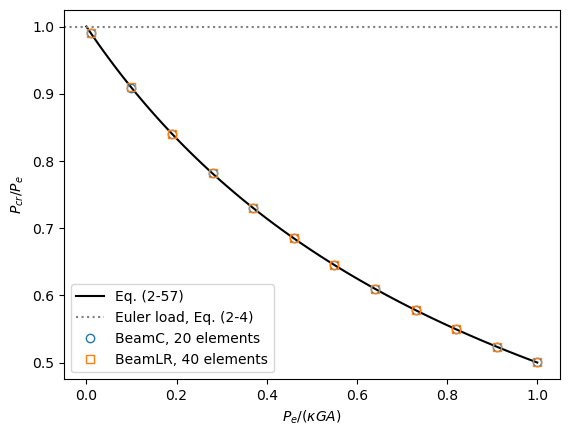

In [5]:
ratios = np.linspace(0.01, 1., 12)
curve = np.linspace(0, 1., 101)
fig, ax = plt.subplots()
ax.plot(curve, 1/(1 + curve), 'k-', label='Eq. (2-57)')
ax.axhline(1., color='gray', ls=':', label='Euler load, Eq. (2-4)')
for name, num_elements, marker in [('BeamC', 20, 'o'), ('BeamLR', 40, 's')]:
    ratio_fe = []
    for shear_ratio in ratios:
        loads, euler, _, kGA = buckling_loads(name, 0.05, 0.05, (1, 2, 3),
                                              (0, 0, 1), num_elements,
                                              shear_ratio=shear_ratio)
        ratio_fe.append(loads[0]/euler)
    ax.plot(ratios, ratio_fe, marker, mfc='none',
            label='%s, %d elements' % (name, num_elements))
ax.set_xlabel(r'$P_e/(\kappa G A)$')
ax.set_ylabel(r'$P_{cr}/P_e$')
ax.legend()
plt.show()

Both elements follow Eq. (2-57); their differences from it fall as the square
of the element length, and are about $10^{-4}$ with these meshes.

## References

- Timoshenko, S. P. and Gere, J. M., Theory of Elastic Stability, 2nd ed.,
  McGraw-Hill, New York, 1961.